# Iris Flower Species Classification using Artificial Neural Network (ANN)

**Objective:** Build an end-to-end ANN classification project using both provided data sources.

**Data sources**
- `Iris.csv`
- `ac0b10f2-e03a-4d09-be8e-4eef37badb79.sqlite`



In [20]:
import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_auc_score
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


## 1. Upload both files

In [21]:
from google.colab import files

uploaded = files.upload()

print("Uploaded:")
for f in uploaded:
    print("-", f)

Saving database.sqlite to database (2).sqlite
Saving Iris.csv to Iris (2).csv
Uploaded:
- database (2).sqlite
- Iris (2).csv


## 2. Define file names

In [22]:
csv_filename = "Iris.csv"
sqlite_filename = "ac0b10f2-e03a-4d09-be8e-4eef37badb79.sqlite"

print("CSV exists:", os.path.exists(csv_filename))
print("SQLite exists:", os.path.exists(sqlite_filename))

CSV exists: True
SQLite exists: True


## 3. Read CSV

In [23]:
df_csv = pd.read_csv(csv_filename)
print("CSV shape:", df_csv.shape)
display(df_csv.head())

CSV shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 4. Read SQLite

In [24]:
import sqlite3
import pandas as pd

# Correct SQLite database
sqlite_path = "/content/database.sqlite"

# Connect to database
conn = sqlite3.connect(sqlite_path)

# Check available tables
tables = pd.read_sql("""
    SELECT name
    FROM sqlite_master
    WHERE type='table';
""", conn)

print("Tables available in the database:")
display(tables)

# Read Iris table
df_sql = pd.read_sql("SELECT * FROM Iris", conn)

print("SQLite data shape:", df_sql.shape)
display(df_sql.head())

# Close connection
conn.close()

Tables available in the database:


,name
0,Iris


SQLite data shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 5. Validate that both files contain the same data

In [25]:
print("CSV columns:", df_csv.columns.tolist())
print("SQLite columns:", df_sql.columns.tolist())
print("CSV shape:", df_csv.shape)
print("SQLite shape:", df_sql.shape)

csv_sorted = df_csv.sort_values(by=df_csv.columns.tolist()).reset_index(drop=True)
sql_sorted = df_sql.sort_values(by=df_sql.columns.tolist()).reset_index(drop=True)

same_columns = list(df_csv.columns) == list(df_sql.columns)
same_records = csv_sorted.equals(sql_sorted)

print("\nSame columns:", same_columns)
print("Same records:", same_records)

CSV columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
SQLite columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
CSV shape: (150, 6)
SQLite shape: (150, 6)

Same columns: True
Same records: True


### Why we do not concatenate

 Concatenating them would create 300 rows containing duplicate flowers. Instead, both sources are used as independent sources and cross-validated for consistency. The validated CSV copy becomes the modeling dataframe.

In [26]:
if not same_columns or not same_records:
    raise ValueError("CSV and SQLite data do not match. Inspect the validation output.")

df = df_csv.copy()
print("Validated modeling dataset:", df.shape)

Validated modeling dataset: (150, 6)


## 6. Data understanding and cleaning

In [27]:
display(df.head())
print("Shape:", df.shape)
df.info()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Shape: (150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [28]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": df.isnull().sum() / len(df) * 100
})
display(missing)

print("Duplicate rows:", df.duplicated().sum())
print("\nSpecies counts:")
display(df["Species"].value_counts())

,Missing Count,Missing %
Id,0,0.0
SepalLengthCm,0,0.0
SepalWidthCm,0,0.0
PetalLengthCm,0,0.0
PetalWidthCm,0,0.0
Species,0,0.0


Duplicate rows: 0

Species counts:


,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


In [29]:
display(df.describe())
display(df.groupby("Species").mean(numeric_only=True))

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,,
Iris-setosa,25.5,5.006,3.418,1.464,0.244
Iris-versicolor,75.5,5.936,2.770,4.260,1.326
Iris-virginica,125.5,6.588,2.974,5.552,2.026


## 7. Exploratory Data Analysis

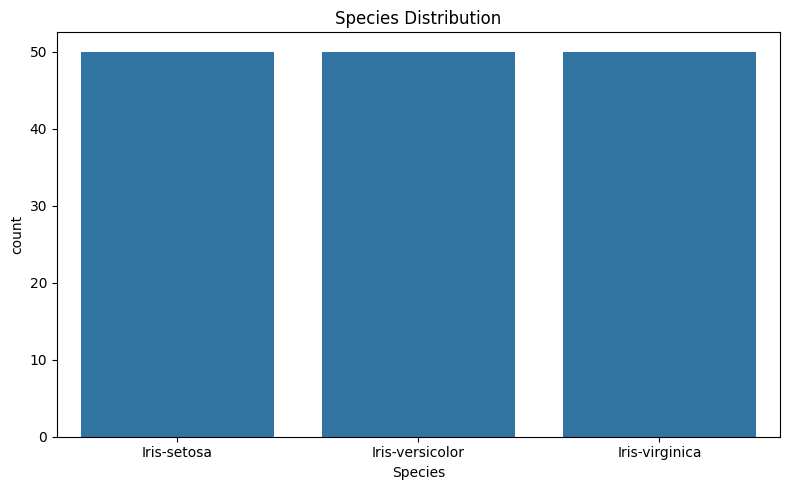

In [30]:
numeric_columns = [
    "SepalLengthCm", "SepalWidthCm",
    "PetalLengthCm", "PetalWidthCm"
]

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Species")
plt.title("Species Distribution")
plt.tight_layout()
plt.show()

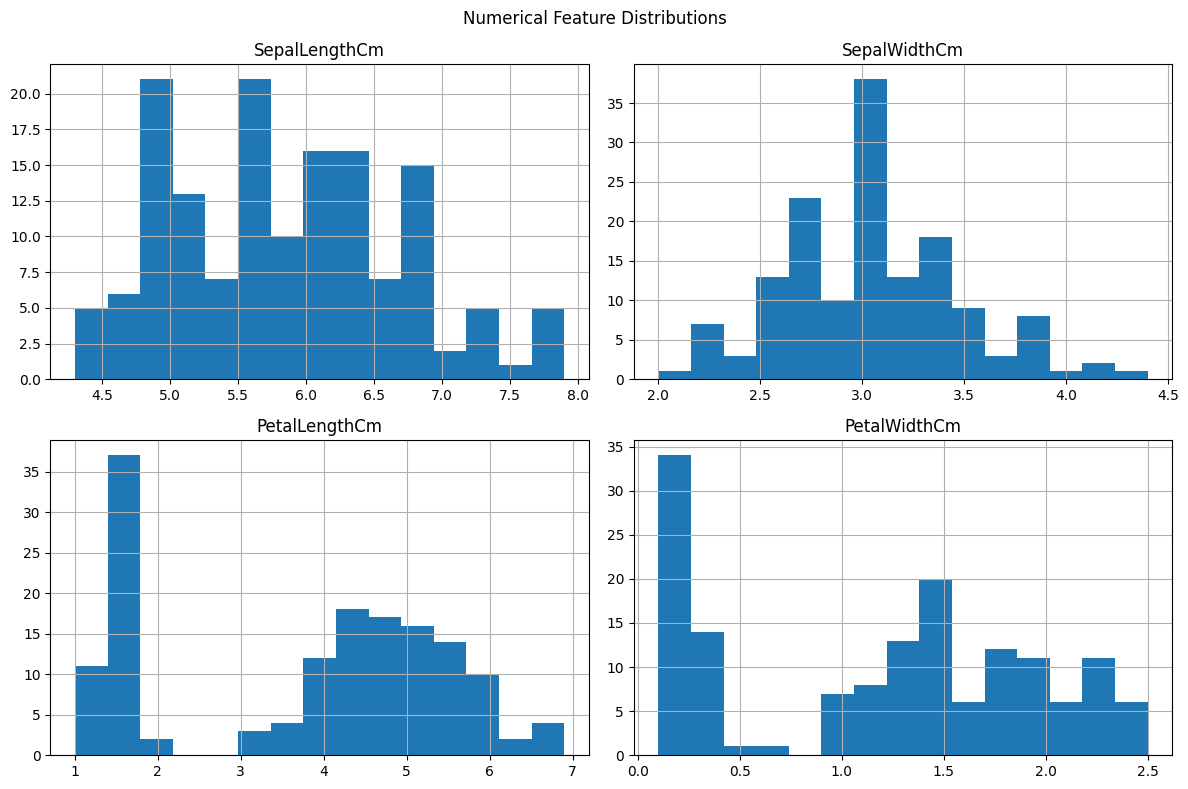

In [31]:
df[numeric_columns].hist(figsize=(12,8), bins=15)
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

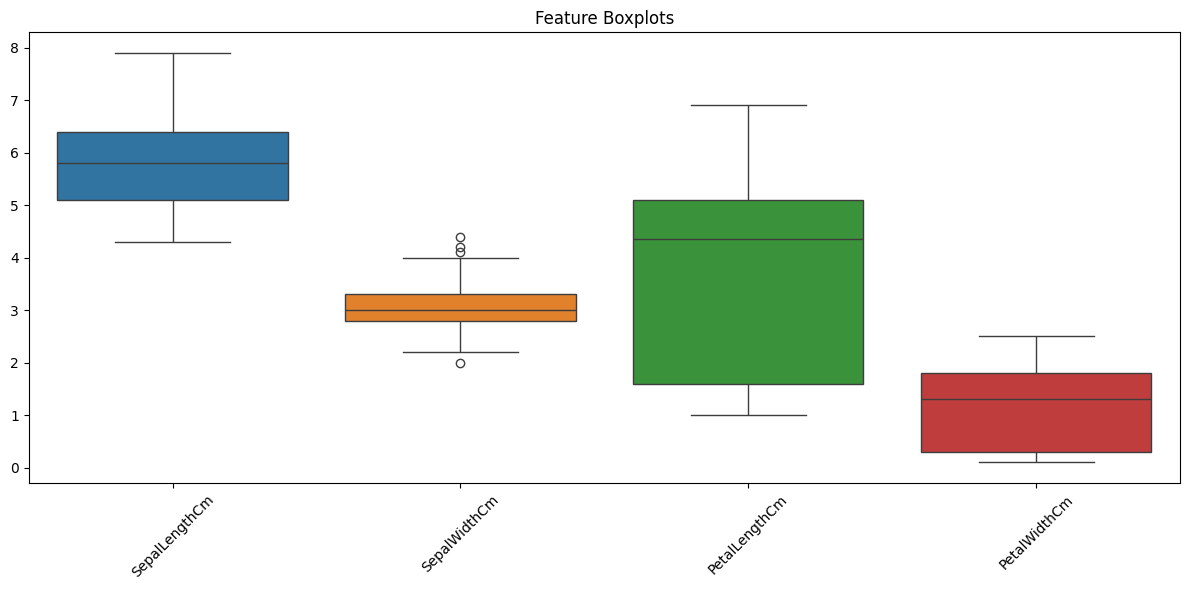

In [32]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df[numeric_columns])
plt.title("Feature Boxplots")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

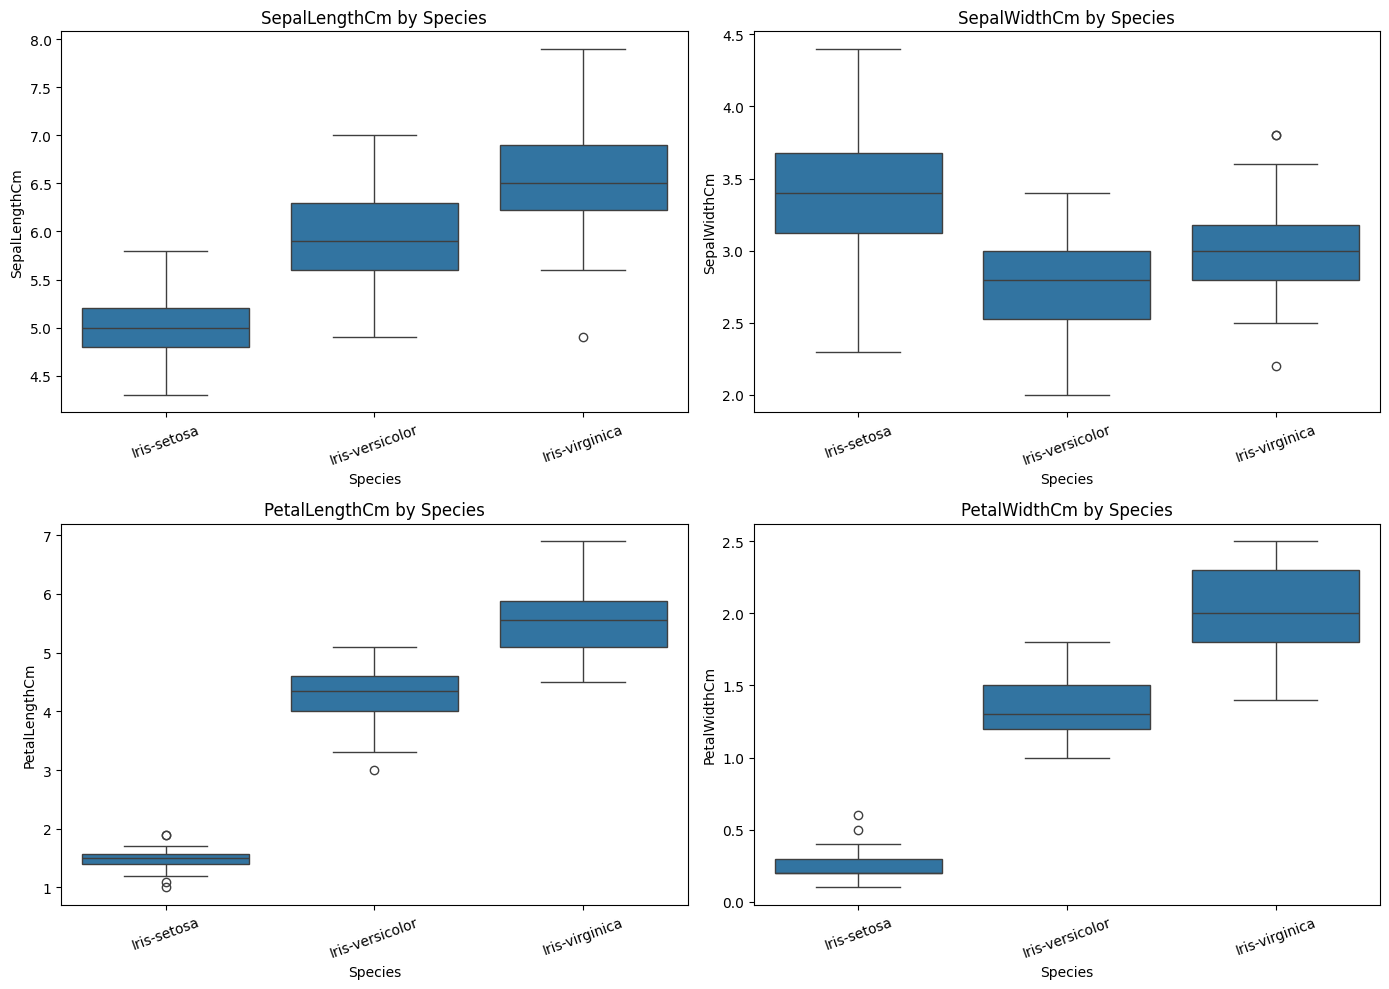

In [33]:
fig, axes = plt.subplots(2,2, figsize=(14,10))
for ax, col in zip(axes.flatten(), numeric_columns):
    sns.boxplot(data=df, x="Species", y=col, ax=ax)
    ax.set_title(f"{col} by Species")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

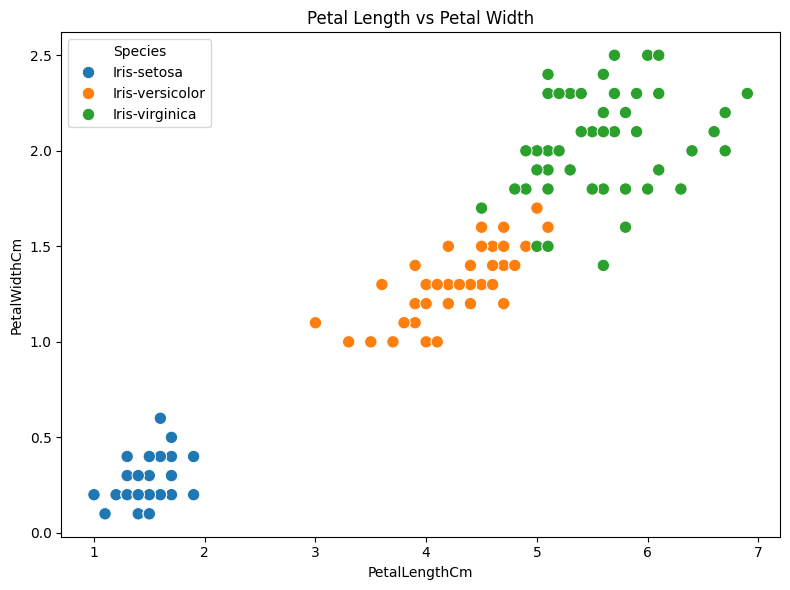

In [34]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="PetalLengthCm", y="PetalWidthCm",
                hue="Species", s=80)
plt.title("Petal Length vs Petal Width")
plt.tight_layout()
plt.show()

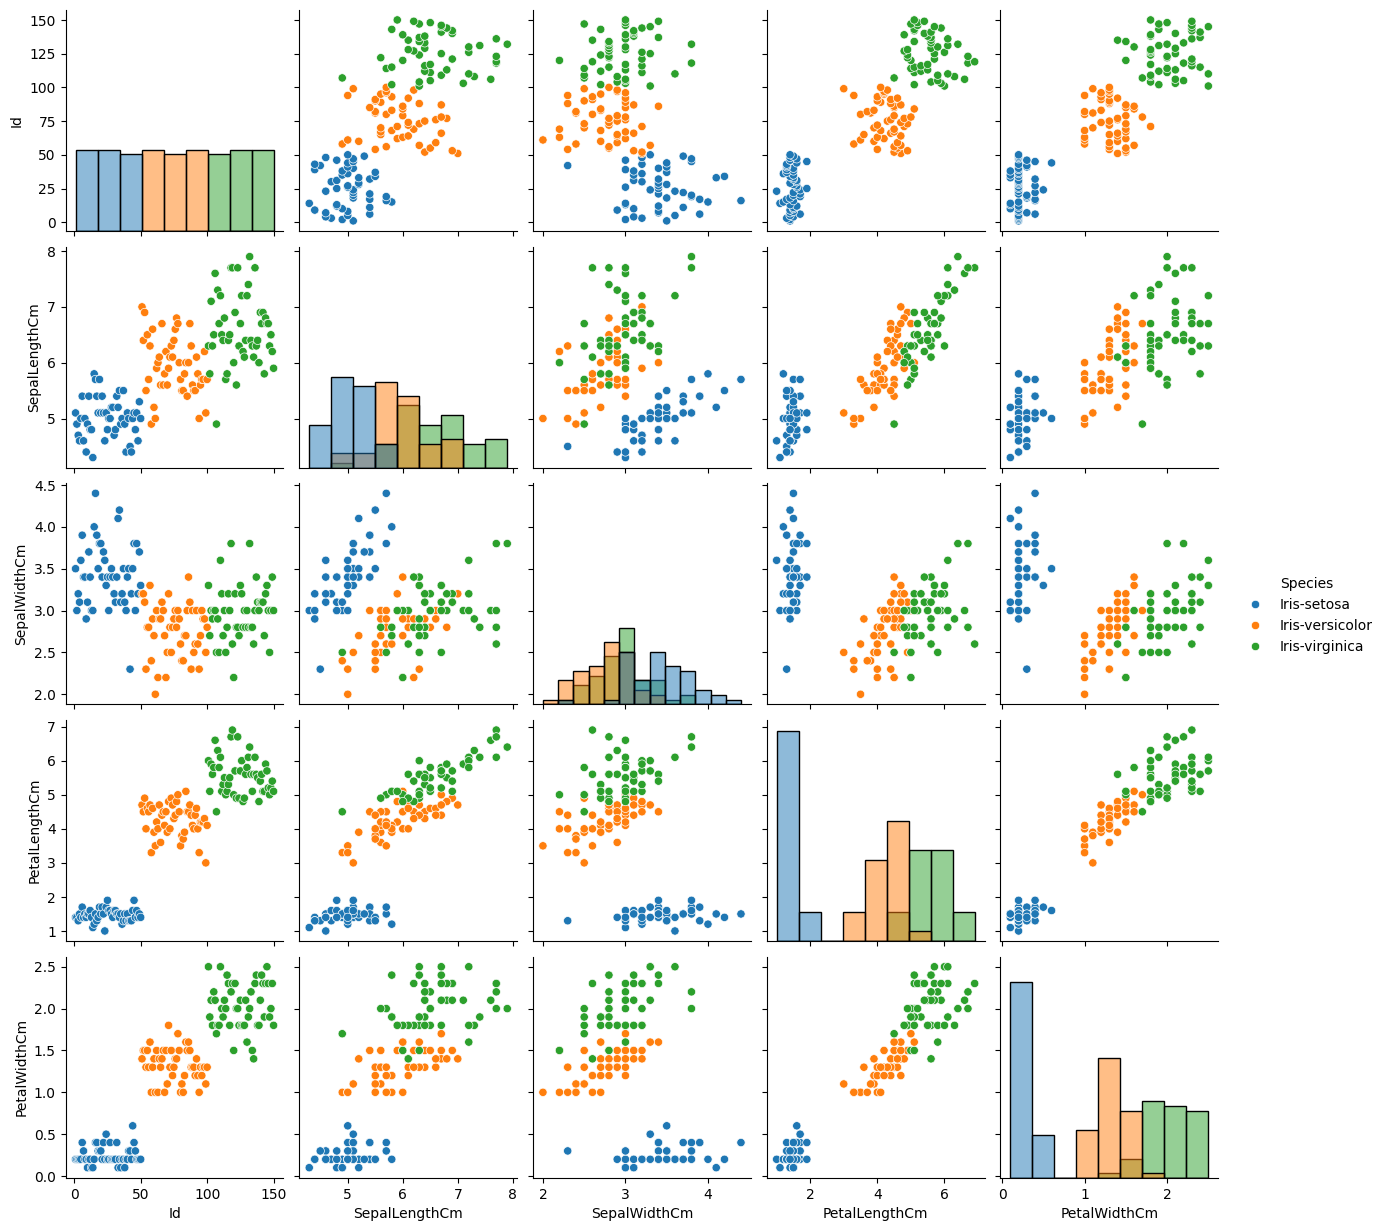

In [35]:
sns.pairplot(df, hue="Species", diag_kind="hist")
plt.show()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
SepalLengthCm,1.000000,-0.109369,0.871754,0.817954
SepalWidthCm,-0.109369,1.000000,-0.420516,-0.356544
PetalLengthCm,0.871754,-0.420516,1.000000,0.962757
PetalWidthCm,0.817954,-0.356544,0.962757,1.000000


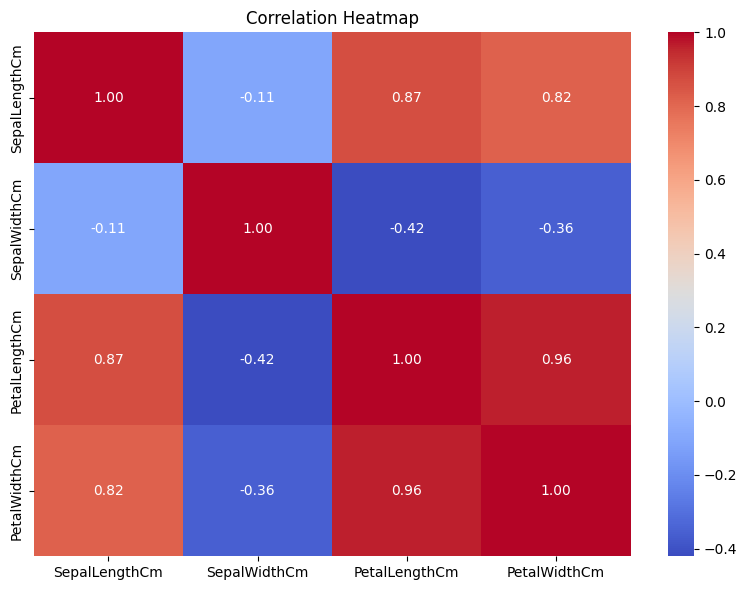

In [36]:
correlation = df[numeric_columns].corr()
display(correlation)

plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Feature engineering

In [37]:
df["PetalArea"] = df["PetalLengthCm"] * df["PetalWidthCm"]
df["SepalArea"] = df["SepalLengthCm"] * df["SepalWidthCm"]
df["PetalLength_SepalLength_Ratio"] = df["PetalLengthCm"] / df["SepalLengthCm"]
df["PetalWidth_SepalWidth_Ratio"] = df["PetalWidthCm"] / df["SepalWidthCm"]

display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,PetalArea,SepalArea,PetalLength_SepalLength_Ratio,PetalWidth_SepalWidth_Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,0.28,17.85,0.274510,0.057143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,0.28,14.70,0.285714,0.066667
2,3,4.7,3.2,1.3,0.2,Iris-setosa,0.26,15.04,0.276596,0.062500
3,4,4.6,3.1,1.5,0.2,Iris-setosa,0.30,14.26,0.326087,0.064516
4,5,5.0,3.6,1.4,0.2,Iris-setosa,0.28,18.00,0.280000,0.055556


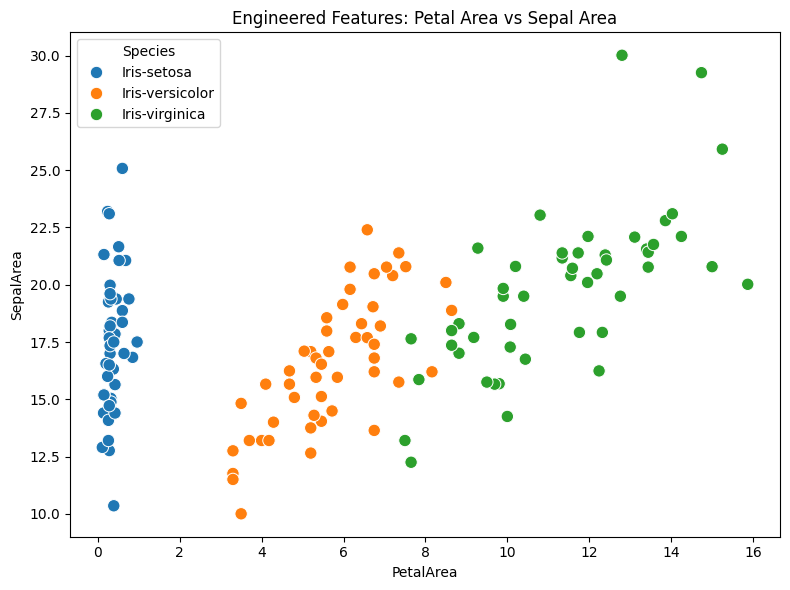

In [38]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="PetalArea", y="SepalArea",
                hue="Species", s=80)
plt.title("Engineered Features: Petal Area vs Sepal Area")
plt.tight_layout()
plt.show()

## 9. Prepare data for ANN

In [39]:
feature_columns = [
    "SepalLengthCm", "SepalWidthCm",
    "PetalLengthCm", "PetalWidthCm",
    "PetalArea", "SepalArea",
    "PetalLength_SepalLength_Ratio",
    "PetalWidth_SepalWidth_Ratio"
]

X = df[feature_columns].copy()
y = df["Species"].copy()

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Number of features:", X.shape[1])

Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Number of features: 8


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (120, 8)
Test: (30, 8)


## 10. Build the Artificial Neural Network

In [41]:
tf.random.set_seed(42)
np.random.seed(42)

ann_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dropout(0.20),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 979 (3.82 KB)

 Trainable params: 979 (3.82 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN compiled.")

ANN compiled.


## 11. Train the ANN

In [43]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=150,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.2708 - loss: 1.2065 - val_accuracy: 0.3750 - val_loss: 1.1474
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.2812 - loss: 1.1746 - val_accuracy: 0.3333 - val_loss: 1.0847
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3229 - loss: 1.0780 - val_accuracy: 0.2083 - val_loss: 1.0356
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3333 - loss: 1.0358 - val_accuracy: 0.4167 - val_loss: 0.9974
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4688 - loss: 0.9956 - val_accuracy: 0.6250 - val_loss: 0.9722
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6146 - loss: 0.9611 - val_accuracy: 0.7500 - val_loss: 0.9385
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6771 - loss: 0.8977 - val_accuracy: 0.7500 - val_loss: 0.8995
Epoch 8/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7708 - loss: 0.8521 - val_accuracy: 0.7917 - val_loss:

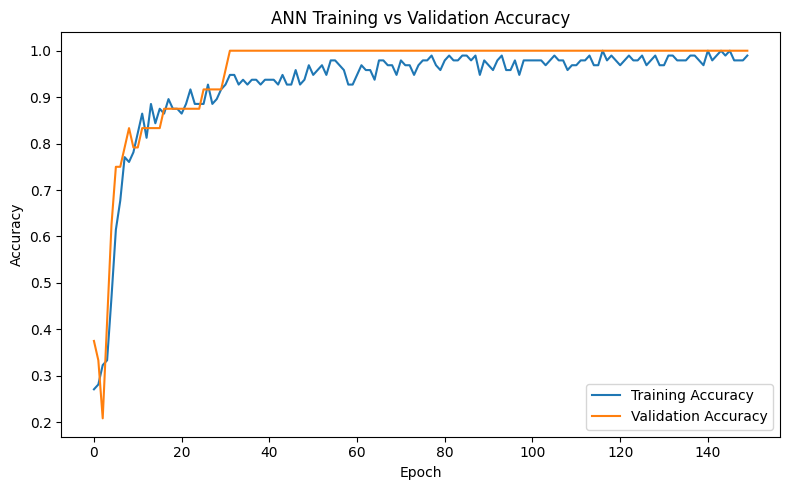

In [44]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

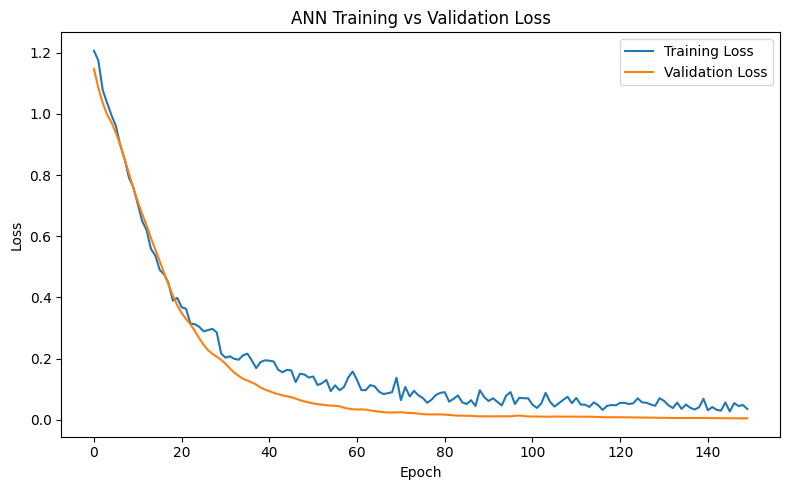

In [45]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Evaluate the ANN

In [46]:
test_loss, test_accuracy = ann_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

Test Loss: 0.1318
Test Accuracy: 0.9333
Test Accuracy: 93.33%


In [47]:
y_probability = ann_model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probability, axis=1)

print(classification_report(
    y_test, y_pred,
    target_names=label_encoder.classes_
))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



In [48]:
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Precision: 0.9333
Recall:    0.9333
F1 Score:  0.9333


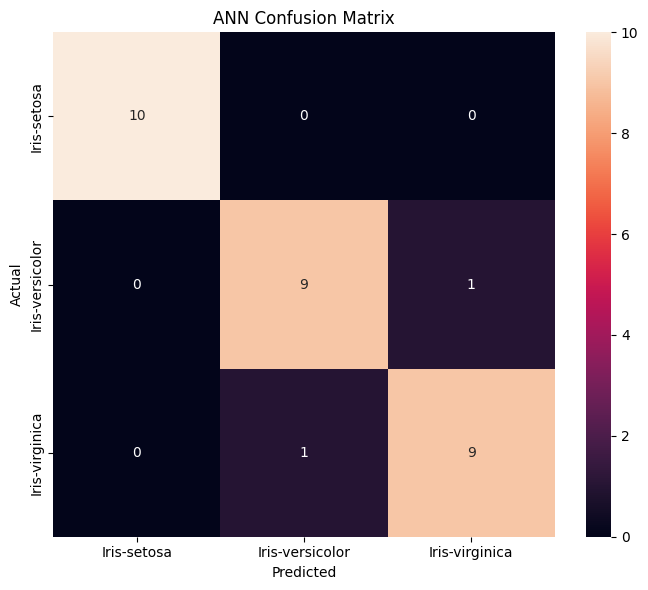

In [49]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

In [50]:
roc_auc = roc_auc_score(
    y_test, y_probability,
    multi_class="ovr",
    average="weighted"
)

print(f"Weighted Multiclass ROC-AUC: {roc_auc:.4f}")

Weighted Multiclass ROC-AUC: 0.9900


## 13. Test a New Flower

In [51]:
new_flower = pd.DataFrame({
    "SepalLengthCm": [5.1],
    "SepalWidthCm": [3.5],
    "PetalLengthCm": [1.4],
    "PetalWidthCm": [0.2]
})

new_flower["PetalArea"] = (
    new_flower["PetalLengthCm"] * new_flower["PetalWidthCm"]
)
new_flower["SepalArea"] = (
    new_flower["SepalLengthCm"] * new_flower["SepalWidthCm"]
)
new_flower["PetalLength_SepalLength_Ratio"] = (
    new_flower["PetalLengthCm"] / new_flower["SepalLengthCm"]
)
new_flower["PetalWidth_SepalWidth_Ratio"] = (
    new_flower["PetalWidthCm"] / new_flower["SepalWidthCm"]
)

new_flower = new_flower[feature_columns]
new_scaled = scaler.transform(new_flower)

probabilities = ann_model.predict(new_scaled, verbose=0)[0]
predicted_class = int(np.argmax(probabilities))
predicted_species = label_encoder.inverse_transform([predicted_class])[0]

print("Predicted species:", predicted_species)
print("\nProbabilities:")
for name, prob in zip(label_encoder.classes_, probabilities):
    print(f"{name}: {prob:.4f}")

Predicted species: Iris-setosa

Probabilities:
Iris-setosa: 1.0000
Iris-versicolor: 0.0000
Iris-virginica: 0.0000


## 14. Save Model and Preprocessing Objects

In [52]:
import joblib

ann_model.save("iris_ann_model.keras")
joblib.dump(scaler, "iris_scaler.pkl")
joblib.dump(label_encoder, "iris_label_encoder.pkl")
joblib.dump(feature_columns, "iris_features.pkl")

print("Saved:")
print("iris_ann_model.keras")
print("iris_scaler.pkl")
print("iris_label_encoder.pkl")
print("iris_features.pkl")

Saved:
iris_ann_model.keras
iris_scaler.pkl
iris_label_encoder.pkl
iris_features.pkl


## 15. Install and Launch Gradio

In [53]:
!pip install -q gradio

In [54]:
import gradio as gr

def predict_species(
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
):
    input_data = pd.DataFrame({
        "SepalLengthCm": [sepal_length],
        "SepalWidthCm": [sepal_width],
        "PetalLengthCm": [petal_length],
        "PetalWidthCm": [petal_width]
    })

    input_data["PetalArea"] = (
        input_data["PetalLengthCm"] * input_data["PetalWidthCm"]
    )
    input_data["SepalArea"] = (
        input_data["SepalLengthCm"] * input_data["SepalWidthCm"]
    )
    input_data["PetalLength_SepalLength_Ratio"] = (
        input_data["PetalLengthCm"] / input_data["SepalLengthCm"]
    )
    input_data["PetalWidth_SepalWidth_Ratio"] = (
        input_data["PetalWidthCm"] / input_data["SepalWidthCm"]
    )

    input_data = input_data[feature_columns]
    input_scaled = scaler.transform(input_data)

    probabilities = ann_model.predict(
        input_scaled, verbose=0
    )[0]

    predicted_class = int(np.argmax(probabilities))
    species = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    probability_dict = {
        label_encoder.classes_[i]: float(probabilities[i])
        for i in range(len(probabilities))
    }

    return species, probability_dict

In [55]:
with gr.Blocks(title="Iris Flower ANN Classifier") as demo:
    gr.Markdown(
        "# 🌸 Iris Flower Species Prediction\n"
        "### Artificial Neural Network Classification"
    )

    with gr.Row():
        sepal_length = gr.Number(value=5.1, label="Sepal Length (cm)")
        sepal_width = gr.Number(value=3.5, label="Sepal Width (cm)")

    with gr.Row():
        petal_length = gr.Number(value=1.4, label="Petal Length (cm)")
        petal_width = gr.Number(value=0.2, label="Petal Width (cm)")

    predict_button = gr.Button("🌸 Predict Species")

    prediction_output = gr.Textbox(label="Predicted Species")
    probability_output = gr.Label(label="Prediction Probabilities")

    predict_button.click(
        predict_species,
        inputs=[
            sepal_length, sepal_width,
            petal_length, petal_width
        ],
        outputs=[
            prediction_output,
            probability_output
        ]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://63a13b9dc958b0d8f6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
